# task 2 -> vision-language model and visual grounding

## imports

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#the scripts use paths relative to the repo root (configs/, data/, results/), so the notebook runs from there
if not Path('configs').exists():
    os.chdir('..')

from common.utils import load_yaml, read_jsonl, repo_path

## global env variables ->

In [2]:
#papermill overrides these for the smoke test, the defaults are the real run
CONFIG = 'configs/task2.yaml'
RUN_SCRIPTS = True #False -> only rebuild the tables and figures from results already on disk

In [3]:
# Parameters
CONFIG = "/mnt/atml/pa3/scaled/task2.yaml"


In [4]:
cfg = load_yaml(CONFIG)
RESULTS = repo_path(cfg['results_dir'])
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATA = repo_path(cfg['data_dir'])
#the exact configuration of this run (smoke / --scale overrides included), kept with its results
import yaml
(RESULTS / 'run_config.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False))

STAGES = [s['name'] for s in cfg['stages']] #caption, instruct, vqa
STAGE_ENDS = np.cumsum([s['updates'] for s in cfg['stages']]).tolist() #2250, 3750, 4500
CONDITIONS = ['correct', 'complementary', 'mismatched', 'none']
SUITES = {'grounding_test': 'annotation-derived grounding', 'vqa_test': 'natural vqav2'}

#one fixed colour per image condition, the same in every figure
COLORS = {'correct': '#2a78d6', 'complementary': '#eb6834', 'mismatched': '#9b59b6', 'none': '#52514e'}

PYTHON = sys.executable #the interpreter running this notebook, so the scripts use the same environment

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2})


def run(command):
    #runs one script as its own process, exactly as it would be typed in a terminal. each script loads its own
    #models and writes its results to disk, nothing is passed through notebook state. finished work is skipped
    if RUN_SCRIPTS:
        get_ipython().system(command)
        assert get_ipython().user_ns['_exit_code'] == 0, f'failed -> {command}'


def load_result(name):
    return json.loads((RESULTS / name).read_text())


def stage_lines(axis):
    #dotted vertical lines at the stage boundaries (end of caption, end of instruct)
    for end in STAGE_ENDS[:-1]:
        axis.axvline(end, color='#b5b3ad', linestyle=':', linewidth=1)


def with_ci(stat, scale=100):
    return f"{scale * stat['mean']:.1f} [{scale * stat['ci_low']:.1f}, {scale * stat['ci_high']:.1f}]"

## data ->

coco 2014 captions, annotation-derived presence/counting pairs and vqav2 complementary pairs, selected with seed 6304. train2014 images for training only, val2014 images for development and final test, every evaluation set image-disjoint from the others. the downloads are cpu work, so on modal this step runs in its own cpu-only container first (`--cpu --cmd`) and is skipped here

In [5]:
run(f'{PYTHON} -m task2_vlm.prepare_data --config {CONFIG}')
#the selection record and the selected ids live next to the splits (shared by every run on this data directory),
#copied into this run's results as the record of the data it used
selection = json.loads((DATA / 'splits' / 'done.json').read_text())
for name, source in [('selection_summary.json', 'done.json'), ('selection_ids.json', 'selection_ids.json')]:
    (RESULTS / name).write_text((DATA / 'splits' / source).read_text())
display(pd.Series({k: v for k, v in selection.items() if k not in ('types', 'rules', 'isolation')}, name='rows'))
display(pd.DataFrame(selection['types']).fillna(0).astype(int).T)
print('isolation ->', selection['isolation'], ' rules ->', selection['rules'])

splits already built -> /root/pa3/data/task2/splits


9266 images, 0 to download
images ready


vqa_train          1536
vqa_test             96
vqa_dev              32
caption_train     18000
presence_pool      5000
counting_pool      5000
grounding_test       64
grounding_dev        24
caption_dev          96
Name: rows, dtype: int64

,yes/no,number,other,presence,counting
vqa_train,640,256,640,0,0
vqa_test,36,24,36,0,0
vqa_dev,12,8,12,0,0
presence_pool,0,0,0,5000,0
counting_pool,0,0,0,0,5000
grounding_test,0,0,0,32,32
grounding_dev,0,0,0,12,12


isolation -> {'train_images': 8738, 'eval_images': 528}  rules -> {'min_object_area': 0.01, 'count_range': [1, 4], 'vqa_min_agreement': 8, 'seed': 6304}


## siglip feature cache ->

the frozen encoder runs once over every used image (196 patch features after siglip's final layer norm, fp16), then leaves the gpu before training

In [6]:
run(f'{PYTHON} -m task2_vlm.cache_features --config {CONFIG}')
#one cache serves every run on this data directory, so its record lives next to the features. copied into the
#results here so each run's results directory carries the caching cost it relied on
cache = json.loads((DATA / 'feature_cache.json').read_text())
(RESULTS / 'feature_cache.json').write_text(json.dumps(cache, indent=2))
display(pd.DataFrame(cache['splits']).T)
print('caching ->', round(cache['seconds'] / 60, 2), 'min, peak memory', cache['peak_memory_gb'], 'gb on', cache['gpu'])

features already cached


,images,shape,seconds,bytes
train2014,8738,"[8738, 196, 768]",125.005376,2630697400
val2014,528,"[528, 196, 768]",24.740784,158961952


caching -> 2.5 min, peak memory 2.363722801208496 gb on NVIDIA RTX PRO 6000 Blackwell Server Edition


## training ->

one continuous run through the three stages (caption alignment, visual instruction tuning, natural vqa), development metrics before training, every 500 updates and at each stage end

In [7]:
run(f'{PYTHON} -m task2_vlm.train --config {CONFIG}')

[dev    0] caption_loss 5.692  grounding_dev_nll_correct 11.298  grounding_dev_nll_complementary 11.229  grounding_dev_nll_none 10.671  grounding_dev_swap_penalty -0.069  vqa_dev_nll_correct 13.082  vqa_dev_nll_complementary 13.039  vqa_dev_nll_none 11.875  vqa_dev_swap_penalty -0.043
[train] stage caption updates 0..2250  warmup 113  trainable 1,837,056


[train] update   25  caption  loss 4.4023  lr 2.21e-04  grad 74.944  0.1 min


[train] update   50  caption  loss 3.3625  lr 4.42e-04  grad 4.042  0.1 min


[train] update   75  caption  loss 3.0658  lr 6.64e-04  grad 2.585  0.2 min


[train] update  100  caption  loss 3.3662  lr 8.85e-04  grad 1.704  0.3 min


[train] update  125  caption  loss 3.1766  lr 1.00e-03  grad 1.395  0.4 min


... (185 outputs left out)

[train] update 4475  vqa      loss 0.6094  lr 5.14e-06  grad 3.513  13.3 min


[train] update 4500  vqa      loss 0.6853  lr 5.00e-06  grad 5.712  13.3 min


[dev 4500] caption_loss 2.534  grounding_dev_nll_correct 0.774  grounding_dev_nll_complementary 3.780  grounding_dev_nll_none 7.598  grounding_dev_swap_penalty 3.006  vqa_dev_nll_correct 1.067  vqa_dev_nll_complementary 3.099  vqa_dev_nll_none 9.510  vqa_dev_swap_penalty 2.032


[train] stage vqa done, weights -> stage_vqa.safetensors
[train] done in 13.3 min, peak memory 4.48 gb


## final evaluation ->

both final-test suites under correct, complementary, mismatched and no-image inputs. greedy, 16 new tokens, batch size 8, thinking disabled

In [8]:
run(f'{PYTHON} -m task2_vlm.evaluate --config {CONFIG}')

`generation_config` default values have been modified to match model-specific defaults: {'do_sample': True, 'temperature': 0.6, 'top_k': 20, 'top_p': 0.95, 'bos_token_id': 151643}. If this is not desired, please set these values explicitly.


[eval] grounding_test  correct       accuracy 0.680  empty 0.000  nll 1.025


[eval] grounding_test  complementary accuracy 0.172  empty 0.000  nll 3.510


[eval] grounding_test  mismatched    accuracy 0.398  empty 0.000  nll 2.182


[eval] grounding_test  none          accuracy 0.000  empty 0.000  nll 8.027


[eval] vqa_test        correct       accuracy 0.537  empty 0.000  nll 1.468


[eval] vqa_test        complementary accuracy 0.206  empty 0.000  nll 2.999


[eval] vqa_test        mismatched    accuracy 0.271  empty 0.000  nll 2.754


[eval] vqa_test        none          accuracy 0.000  empty 0.000  nll 10.023


[eval] done in 0.5 min


## interface checks and connector calibration

In [9]:
checks = load_result('interface_checks.json')
display(pd.Series({k: v for k, v in checks.items() if k != 'prompt_layout'}, name='value').to_frame())
print('prompt layout ->')
print(checks['prompt_layout'])
display(pd.Series(load_result('calibration.json'), name='value').to_frame())

,value
feature_bank_shape,"[9266, 196, 768]"
feature_dtype,torch.float16
visual_tokens,196
backbone_trainable,0
lora_trainable_in_stage_1,0
connector_grad_norm,324.048004
backbone_or_lora_grads,0
split_isolation,"{'train_images': 8738, 'eval_images': 528}"


prompt layout ->
<|im_start|>user
[196 visual tokens]
Describe this image in one sentence.<|im_end|>
<|im_start|>assistant
<think>

</think>

They are brave for riding in the jungle on those elephants.<|im_end|>


,value
rule,mean L2 norm of caption-token input embeddings...
images,1024
text_tokens,36224
text_mean_norm,0.872606
visual_mean_norm_unscaled,15.916479
scale,0.054824


## learning curves ->

training loss with the stage boundaries (dotted), development caption loss, reference-answer nll under correct, complementary and no-image inputs, and the image-swap penalty dNLL = NLL(partner image) - NLL(correct image)

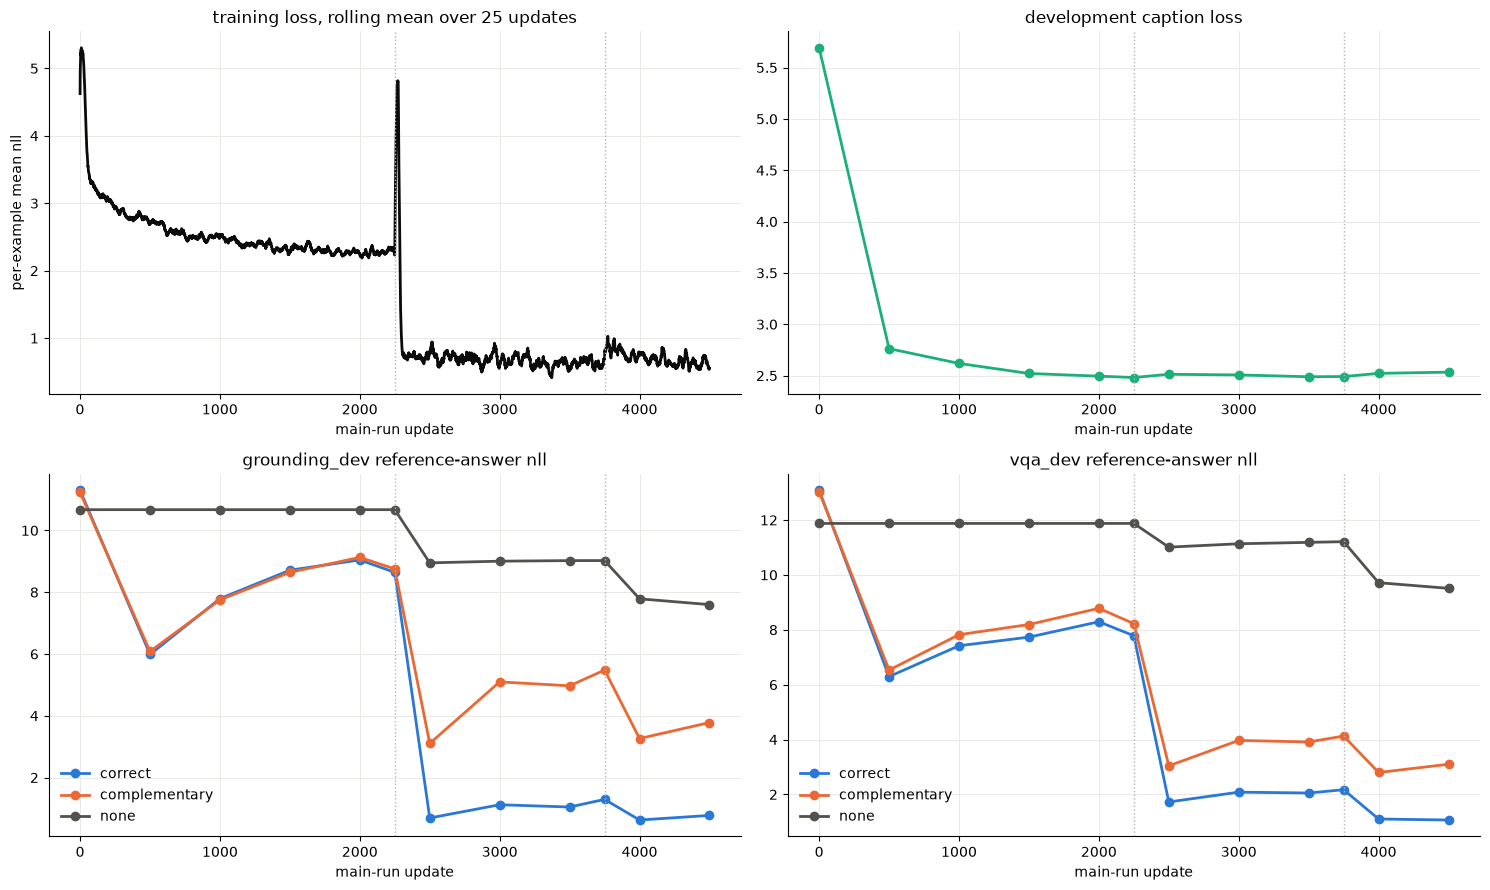

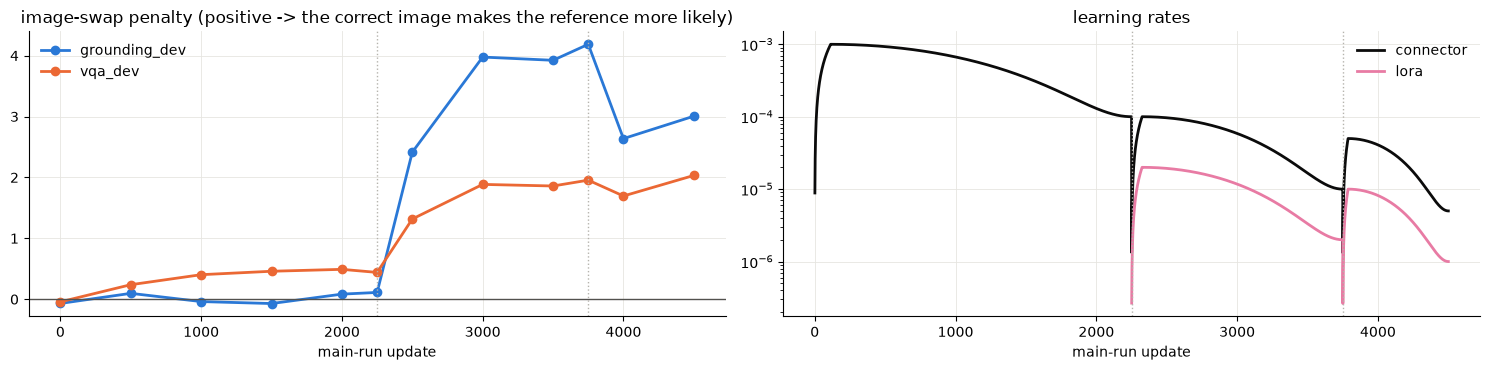

,update,caption_loss,grounding_dev_nll_correct,grounding_dev_nll_complementary,grounding_dev_nll_none,grounding_dev_swap_penalty,vqa_dev_nll_correct,vqa_dev_nll_complementary,vqa_dev_nll_none,vqa_dev_swap_penalty
0,0,5.692,11.298,11.229,10.671,-0.069,13.082,13.039,11.875,-0.043
1,500,2.763,5.985,6.082,10.671,0.096,6.294,6.532,11.875,0.238
2,1000,2.619,7.792,7.753,10.671,-0.039,7.418,7.821,11.875,0.403
3,1500,2.521,8.713,8.642,10.671,-0.071,7.732,8.191,11.875,0.459
4,2000,2.495,9.044,9.127,10.671,0.084,8.292,8.782,11.875,0.491
5,2250,2.482,8.642,8.754,10.671,0.111,7.783,8.223,11.875,0.440
6,2500,2.513,0.691,3.105,8.950,2.414,1.724,3.041,11.011,1.317
7,3000,2.507,1.120,5.097,9.004,3.976,2.082,3.968,11.134,1.885
8,3500,2.489,1.046,4.970,9.022,3.923,2.051,3.911,11.186,1.859
9,3750,2.491,1.293,5.479,9.024,4.186,2.172,4.127,11.211,1.955


In [10]:
log = pd.DataFrame(read_jsonl(RESULTS / 'train_log.jsonl'))
dev = pd.DataFrame(read_jsonl(RESULTS / 'dev_log.jsonl'))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axis = axes[0, 0]
axis.plot(log['update'], log['loss'].rolling(25, min_periods=1).mean(), color='#0b0b0b')
axis.set_title('training loss, rolling mean over 25 updates')
axis.set_ylabel('per-example mean nll')
axis = axes[0, 1]
axis.plot(dev['update'], dev['caption_loss'], marker='o', color='#1baf7a')
axis.set_title('development caption loss')
for axis, suite in zip(axes[1], ['grounding_dev', 'vqa_dev']):
    for condition in ['correct', 'complementary', 'none']:
        axis.plot(dev['update'], dev[f'{suite}_nll_{condition}'], marker='o', color=COLORS[condition], label=condition)
    axis.set_title(f'{suite} reference-answer nll')
    axis.legend(frameon=False)
for axis in axes.flat:
    stage_lines(axis)
    axis.set_xlabel('main-run update')
fig.tight_layout()
fig.savefig(FIGURES / 'learning_curves.png', dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for suite, color in [('grounding_dev', '#2a78d6'), ('vqa_dev', '#eb6834')]:
    axes[0].plot(dev['update'], dev[f'{suite}_swap_penalty'], marker='o', color=color, label=suite)
axes[0].axhline(0, color='#52514e', linewidth=1)
axes[0].set_title('image-swap penalty (positive -> the correct image makes the reference more likely)')
axes[0].legend(frameon=False)
axes[1].plot(log['update'], log['lr_connector'], color='#0b0b0b', label='connector')
axes[1].plot(log['update'], log['lr_lora'], color='#e87ba4', label='lora')
axes[1].set_yscale('log')
axes[1].set_title('learning rates')
axes[1].legend(frameon=False)
for axis in axes:
    stage_lines(axis)
    axis.set_xlabel('main-run update')
fig.tight_layout()
fig.savefig(FIGURES / 'swap_penalty_and_lr.png', dpi=200)
plt.show()
dev.to_csv(RESULTS / 'dev_metrics.csv', index=False)
display(dev.round(3))

## curriculum mixture -> examples drawn per component in each stage

In [11]:
summary = load_result('train_summary.json')
mixture = pd.DataFrame(summary['mixture_examples']).fillna(0).astype(int).T
display(pd.concat([mixture, (100 * mixture.div(mixture.sum(axis=1), axis=0)).round(1).add_suffix(' %')], axis=1))
print('updates skipped by the gradient scaler ->', summary['skipped_updates'])
print('content-cap truncations ->', summary['truncated'])

,caption,presence,counting,vqa,caption %,presence %,counting %,vqa %
caption,36000,0,0,0,100.0,0.0,0.0,0.0
instruct,6012,11974,6014,0,25.0,49.9,25.1,0.0
vqa,1152,1226,1230,8392,9.6,10.2,10.2,69.9


updates skipped by the gradient scaler -> [1, 2, 3, 4, 5, 7]
content-cap truncations -> {'question': 0, 'target': 0}


## final results ->

per suite and image condition. accuracy -> normalized exact match (grounding) or vqa soft consensus accuracy (vqav2), pair accuracy -> both questions of a pair match their own canonical answers, identical -> both predictions of a pair are the same, partner match -> a prediction equals the partner image's answer. intervals -> 95%, 4,000 bootstrap resamples of complete pairs

annotation-derived grounding -> 64 pairs


,condition,accuracy,pair_accuracy,answer_nll,identical_%,empty_%,partner_match_%,ms_per_answer
0,correct,"68.0 [58.6, 76.6]","53.1 [40.6, 65.6]","1.0 [0.7, 1.4]",17.19,0.0,12.50,12.57
1,complementary,"17.2 [10.9, 23.4]","1.6 [0.0, 4.7]","3.5 [3.1, 3.9]",23.44,0.0,64.84,8.09
2,mismatched,"39.8 [33.6, 46.9]","6.2 [1.6, 12.5]","2.2 [1.9, 2.4]",67.19,0.0,39.84,8.11
3,none,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","8.0 [7.4, 8.6]",25.00,0.0,0.00,54.60


natural vqav2 -> 96 pairs


,condition,accuracy,pair_accuracy,answer_nll,identical_%,empty_%,partner_match_%,ms_per_answer
0,correct,"53.8 [45.7, 61.6]","31.2 [21.9, 40.6]","1.5 [1.2, 1.8]",36.46,0.0,19.79,10.99
1,complementary,"20.6 [15.3, 26.1]","3.1 [0.0, 7.3]","3.0 [2.6, 3.4]",29.17,0.0,51.56,11.28
2,mismatched,"27.1 [20.9, 33.2]","4.2 [1.0, 8.3]","2.8 [2.3, 3.2]",53.12,0.0,28.12,11.20
3,none,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","10.0 [9.4, 10.7]",20.83,0.0,0.00,63.49


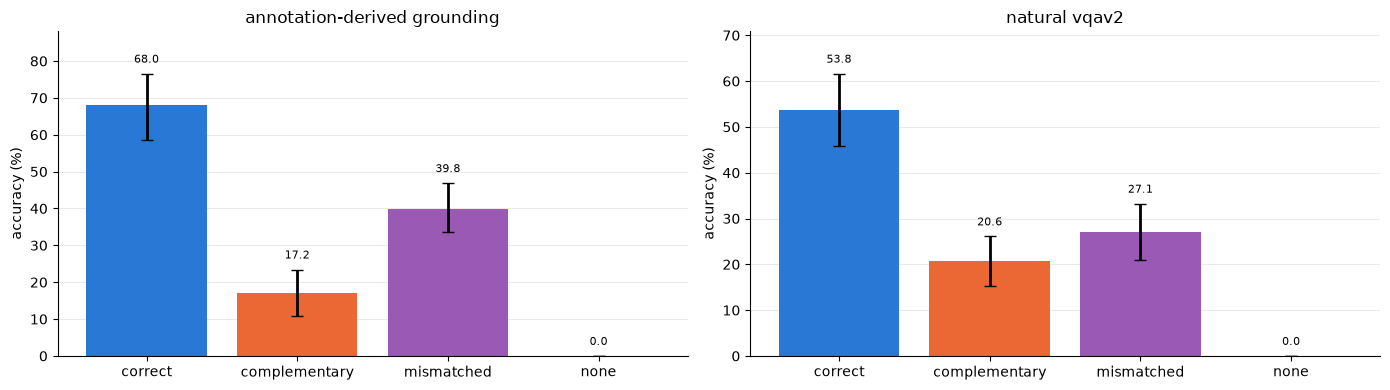

In [12]:
final = load_result('eval_final.json')['summary']
tables = {}
for suite, title in SUITES.items():
    rows = []
    for c in CONDITIONS:
        s = final[suite]['conditions'][c]
        rows.append({'condition': c, 'accuracy': with_ci(s['accuracy']), 'pair_accuracy': with_ci(s['pair_accuracy']),
                     'answer_nll': with_ci(s['nll'], scale=1), 'identical_%': 100 * s['identical_rate'],
                     'empty_%': 100 * s['empty_rate'], 'partner_match_%': 100 * s['partner_match_rate'],
                     'ms_per_answer': 1000 * s['seconds_per_answer']})
    tables[suite] = pd.DataFrame(rows)
    tables[suite].to_csv(RESULTS / f'final_{suite}.csv', index=False)
    print(f"{title} -> {final[suite]['pairs']} pairs")
    display(tables[suite].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for axis, suite in zip(axes, SUITES):
    stats = [final[suite]['conditions'][c]['accuracy'] for c in CONDITIONS]
    means = [100 * s['mean'] for s in stats]
    errors = [[100 * (s['mean'] - s['ci_low']) for s in stats], [100 * (s['ci_high'] - s['mean']) for s in stats]]
    bars = axis.bar(CONDITIONS, means, yerr=errors, capsize=4, color=[COLORS[c] for c in CONDITIONS])
    axis.bar_label(bars, fmt='%.1f', padding=6, fontsize=8)
    axis.set_title(SUITES[suite])
    axis.set_ylabel('accuracy (%)')
    axis.grid(axis='x', visible=False)
    axis.margins(y=0.15)
fig.tight_layout()
fig.savefig(FIGURES / 'final_accuracy.png', dpi=200)
plt.show()

In [13]:
#by question type -> presence / counting (grounding) and yes/no / number / other (vqav2)
rows = []
for suite in SUITES:
    for t, by_condition in final[suite]['types'].items():
        rows.append({'suite': suite, 'type': t, **{c: with_ci(by_condition[c]['accuracy']) for c in CONDITIONS},
                     **{f'{c}_pair': with_ci(by_condition[c]['pair_accuracy']) for c in CONDITIONS}})
types = pd.DataFrame(rows)
types.to_csv(RESULTS / 'final_types.csv', index=False)
display(types)

#correct-image advantages over complementary swaps, on matched pairs -> accuracy in pp, nll in nats
advantages = pd.DataFrame([{'suite': suite, 'accuracy_advantage_pp': with_ci(final[suite]['advantages']['accuracy']),
                            'nll_advantage': with_ci(final[suite]['advantages']['nll'], scale=1)} for suite in SUITES])
advantages.to_csv(RESULTS / 'advantages.csv', index=False)
display(advantages)

,suite,type,correct,complementary,mismatched,none,correct_pair,complementary_pair,mismatched_pair,none_pair
0,grounding_test,counting,"43.8 [31.2, 56.2]","20.3 [12.5, 28.1]","28.1 [18.8, 39.1]","0.0 [0.0, 0.0]","21.9 [9.4, 37.5]","0.0 [0.0, 0.0]","6.2 [0.0, 15.6]","0.0 [0.0, 0.0]"
1,grounding_test,presence,"92.2 [85.9, 98.4]","14.1 [6.2, 23.4]","51.6 [46.9, 56.2]","0.0 [0.0, 0.0]","84.4 [71.9, 96.9]","3.1 [0.0, 9.4]","6.2 [0.0, 15.6]","0.0 [0.0, 0.0]"
2,vqa_test,number,"50.6 [33.3, 67.9]","15.8 [6.9, 25.0]","9.0 [2.1, 17.3]","0.0 [0.0, 0.0]","37.5 [20.8, 58.3]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]"
3,vqa_test,other,"39.2 [26.7, 51.8]","9.0 [3.2, 16.0]","7.2 [2.2, 13.5]","0.0 [0.0, 0.0]","22.2 [8.3, 36.1]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]"
4,vqa_test,yes/no,"70.4 [62.1, 78.6]","35.4 [25.7, 45.3]","59.0 [53.1, 65.6]","0.0 [0.0, 0.0]","36.1 [22.2, 52.8]","8.3 [0.0, 19.4]","11.1 [2.8, 22.2]","0.0 [0.0, 0.0]"


,suite,accuracy_advantage_pp,nll_advantage
0,grounding_test,"50.8 [37.5, 63.3]","2.5 [1.9, 3.0]"
1,vqa_test,"33.1 [24.2, 42.1]","1.5 [1.1, 2.0]"


## complementary-image examples ->

selection rule, fixed before looking at any output -> the first pair of every question type in the final-test file order (the seeded selection order), shown under all four image conditions. no filtering by outcome

In [14]:
examples = pd.DataFrame(read_jsonl(RESULTS / 'eval_final_examples.jsonl'))
chosen = examples[examples['condition'] == 'correct'].groupby(['suite', 'type'], sort=False)['pair_id'].first()
for (suite, t), pid in chosen.items():
    rows = examples[examples['pair_id'] == pid]
    first = rows.iloc[0]
    print(f"\n{suite} / {t} -> {first['question']}")
    table = rows.pivot_table(index='slot', columns='condition', values='prediction', aggfunc='first')[CONDITIONS]
    table.insert(0, 'reference', rows.groupby('slot')['target'].first())
    table.insert(1, 'image', rows[rows['condition'] == 'correct'].set_index('slot')['image'])
    display(table)


grounding_test / presence -> Does this image contain a toilet?


condition,reference,image,correct,complementary,mismatched,none
slot,,,,,,
0,yes,val2014/99747,yes,no,no,"No, the image does not contain a toilet."
1,no,val2014/516415,no,yes,no,"No, the image does not contain a toilet."



grounding_test / counting -> How many airplanes can you see?


condition,reference,image,correct,complementary,mismatched,none
slot,,,,,,
0,1,val2014/355057,2,2,0,"It depends on the location, time of day, and t..."
1,2,val2014/165937,2,3,1,The question is a play on words and can be ans...



vqa_test / yes/no -> Is this a kitchen?


condition,reference,image,correct,complementary,mismatched,none
slot,,,,,,
0,no,val2014/146738,no,yes,no,"No, this is not a kitchen."
1,yes,val2014/288161,yes,no,no,"No, this is not a kitchen."



vqa_test / number -> What many people appear to be dining?


condition,reference,image,correct,complementary,mismatched,none
slot,,,,,,
0,4,val2014/356248,dining,all,donut,"The question is a bit ambiguous. However, if y..."
1,6,val2014/106272,food,dining,dining,It depends on the context and the specific loc...



vqa_test / other -> The people are using umbrellas to block what?


condition,reference,image,correct,complementary,mismatched,none
slot,,,,,,
0,sun,val2014/183166,road,the road,door,The people are using umbrellas to block **rain**.
1,rain,val2014/314515,traffic,cars,parking lot,The people are using umbrellas to block **rain**.


## resources

In [15]:
evaluation = load_result('eval_final.json')
rows = [{'step': 'feature caching (siglip, once)', 'minutes': cache['seconds'] / 60, 'peak_memory_gb': cache['peak_memory_gb'],
         'trainable_params': 0}]
for stage in STAGES:
    rows.append({'step': f'training -> {stage}', 'minutes': summary['train_seconds_by_stage'][stage] / 60,
                 'peak_memory_gb': summary['peak_memory_gb'], 'trainable_params': summary['trainable_by_stage'][stage]})
rows.append({'step': 'development evaluation (all points)', 'minutes': summary['dev_seconds'] / 60,
             'peak_memory_gb': summary['dev_peak_memory_gb']})
rows.append({'step': 'checkpoint i/o', 'minutes': summary['checkpoint_seconds'] / 60})
rows.append({'step': 'final evaluation (generation + nll)', 'minutes': evaluation['seconds'] / 60})
resources = pd.DataFrame(rows)
resources.to_csv(RESULTS / 'resources.csv', index=False)
display(resources.round(3))
print(f"training -> micro batch {summary['micro_batch']} x accumulation {summary['grad_accum']}, "
      f"gradient checkpointing {summary['gradient_checkpointing']}, on {summary['gpu']}")
print('generation time per answer (ms) ->', {s: {c: round(1000 * final[s]['conditions'][c]['seconds_per_answer'], 2)
                                                  for c in CONDITIONS} for s in SUITES})

,step,minutes,peak_memory_gb,trainable_params
0,"feature caching (siglip, once)",2.497,2.364,0.0
1,training -> caption,6.357,4.481,1837056.0
2,training -> instruct,4.653,4.481,6424576.0
3,training -> vqa,2.318,4.481,6424576.0
4,development evaluation (all points),0.156,4.768,NaN
5,checkpoint i/o,0.049,NaN,NaN
6,final evaluation (generation + nll),0.534,NaN,NaN


training -> micro batch 16 x accumulation 1, gradient checkpointing True, on NVIDIA RTX PRO 6000 Blackwell Server Edition
generation time per answer (ms) -> {'grounding_test': {'correct': 12.57, 'complementary': 8.09, 'mismatched': 8.11, 'none': 54.6}, 'vqa_test': {'correct': 10.99, 'complementary': 11.28, 'mismatched': 11.2, 'none': 63.49}}
